# 🧹 Jigsaw: Toxic Comment Classification — Exploratory Data Analysis

**Kaggle challenge:** [jigsaw-toxic-comment-classification-challenge](https://www.kaggle.com/competitions/jigsaw-toxic-comment-classification-challenge)

The task: given a comment from a Wikipedia talk page, predict which of **6 toxicity labels** apply:

| label | meaning |
|---|---|
| `toxic` | rude, disrespectful, or likely to make someone leave a discussion |
| `severe_toxic` | extreme hatred, threats of violence, sexual harassment |
| `obscene` | profanity / obscene language |
| `threat` | threats of harm |
| `insult` | insults and hateful language toward a person |
| `identity_hate` | hate speech targeting identity (race, gender, religion, ...) |

This is a **multi-label** problem: one comment can carry several labels simultaneously (unlike multi-class, where exactly one applies).

In this notebook we answer, with charts:
1. How imbalanced are the classes?
2. How multi-label is it really? Do labels co-occur?
3. Do toxic comments look different structurally (length)?
4. What vocabulary defines each class?

Each figure is saved to `figures/` as a PNG.

## 1. Setup

Imports + consistent styling. `seaborn.set_theme` gives us clean defaults for every chart in one line.

In [1]:
%matplotlib inline
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer
from wordcloud import WordCloud

sns.set_theme(style='whitegrid', context='talk')
pd.set_option('display.max_colwidth', 100)

print('pandas', pd.__version__, '| numpy', np.__version__)

pandas 3.1.1 | numpy 2.4.6


In [2]:
# Locate the project root no matter where the kernel's working directory is:
# walk upward until we find the 'data' directory.
def find_project_root(marker='data'):
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / marker).is_dir():
            return p
    raise FileNotFoundError(f"No '{marker}/' found above {Path.cwd()}")

ROOT = find_project_root()
DATA_DIR = ROOT / 'data'
FIG_DIR = ROOT / 'figures'
FIG_DIR.mkdir(exist_ok=True)
print('project root:', ROOT)

LABELS = ['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']

# Display names for chart titles, and a fixed palette so 'toxic' is always red,
# 'clean' always blue — consistency makes charts comparable at a glance.
PRETTY = {
    'toxic': 'Toxic',
    'severe_toxic': 'Severe toxic',
    'obscene': 'Obscene',
    'threat': 'Threat',
    'insult': 'Insult',
    'identity_hate': 'Identity hate',
}
C_CLEAN, C_TOXIC, C_MAIN = '#4C72B0', '#C44E52', '#55A868'
print('labels:', LABELS)

project root: C:\Users\djame\Downloads\NLP\Jiggsaw
labels: ['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']


## 2. Load the data & sanity checks

Always start with the boring-but-critical checks: shape, missing values, duplicates. A surprise here (e.g. 5% missing comments) would change every downstream decision.

In [3]:
df = pd.read_csv(DATA_DIR / 'train.csv')
print(f'shape: {df.shape[0]:,} comments x {df.shape[1]} columns')
print(f'missing values total : {int(df.isna().sum().sum())}')
print(f'duplicate ids        : {int(df['id'].duplicated().sum())}')
df.head(3)

shape: 159,571 comments x 8 columns
missing values total : 0
duplicate ids        : 0


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my username Hardcore Metallica Fan were reverted? They wer...,0,0,0,0,0,0
1,000103f0d9cfb60f,"D'aww! He matches this background colour I'm seemingly stuck with. Thanks. (talk) 21:51, Januar...",0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It's just that this guy is constantly removing relev...",0,0,0,0,0,0


### Label distribution

Count how many comments carry each label, and how many comments are entirely clean.

In [4]:
counts = df[LABELS].sum()
n = len(df)
n_clean = int((df[LABELS].sum(axis=1) == 0).sum())

print(f'clean comments          : {n_clean:,} ({n_clean / n:.1%})')
print(f'comments with >=1 label : {n - n_clean:,} ({(n - n_clean) / n:.1%})')
pd.DataFrame({'comments': counts, 'pct_of_all': (counts / n).round(4)})

clean comments          : 143,346 (89.8%)
comments with >=1 label : 16,225 (10.2%)


,comments,pct_of_all
toxic,15294,0.0958
severe_toxic,1595,0.0100
obscene,8449,0.0529
threat,478,0.0030
insult,7877,0.0494
identity_hate,1405,0.0088


### Derived text features

Length features are cheap to compute and surprisingly predictive (toxic comments tend to be short rants). We also build `n_labels` (how many labels a comment has) and the binary `is_toxic` (any label at all) — both used repeatedly below.

In [5]:
df['n_chars'] = df['comment_text'].str.len()
df['n_words'] = df['comment_text'].str.split().str.len()
df['n_labels'] = df[LABELS].sum(axis=1)
df['is_toxic'] = (df['n_labels'] > 0).astype(int)

df[['comment_text', 'n_words', 'n_chars', 'n_labels'] + LABELS].head(5)

,comment_text,n_words,n_chars,n_labels,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,Explanation\nWhy the edits made under my username Hardcore Metallica Fan were reverted? They wer...,43,264,0,0,0,0,0,0,0
1,"D'aww! He matches this background colour I'm seemingly stuck with. Thanks. (talk) 21:51, Januar...",17,112,0,0,0,0,0,0,0
2,"Hey man, I'm really not trying to edit war. It's just that this guy is constantly removing relev...",42,233,0,0,0,0,0,0,0
3,"""\nMore\nI can't make any real suggestions on improvement - I wondered if the section statistics...",113,622,0,0,0,0,0,0,0
4,"You, sir, are my hero. Any chance you remember what page that's on?",13,67,0,0,0,0,0,0,0


## 3. Figure 1 — Label counts: the class imbalance problem

**Why we look at this:** with `toxic` at ~10% of data and `threat` at ~0.3%, accuracy is a useless metric here (a model predicting 'all clean' scores 90%). It also tells us later that we'll need per-class metrics, class weights, or stratified sampling — and that `threat`/`identity_hate` will be hard to learn from so few examples.

**Note the log scale:** without it, the small bars would be invisible pixels.

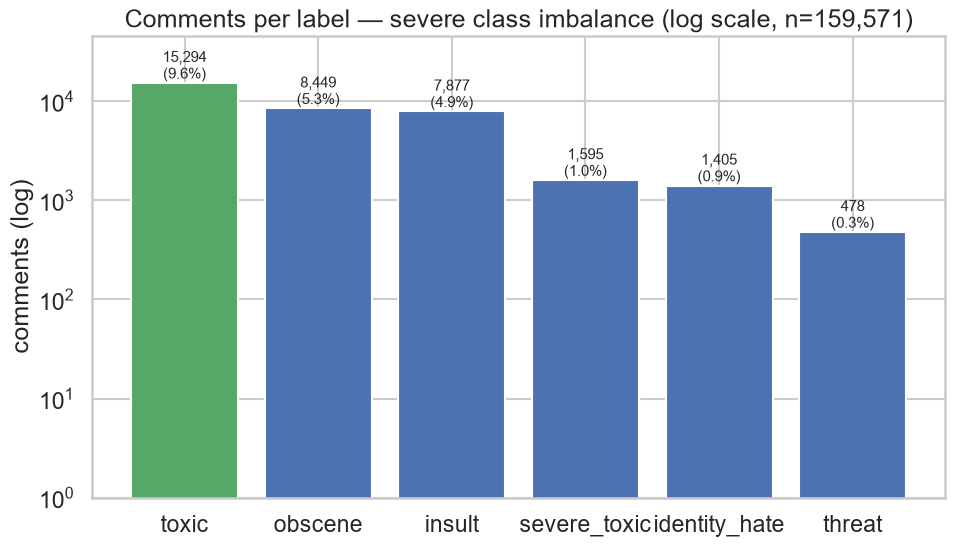

In [6]:
fig, ax = plt.subplots(figsize=(11, 6))
order = counts.sort_values(ascending=False)
bars = ax.bar(order.index, order.values, color=[C_MAIN] + [C_CLEAN] * 5)
for b, v in zip(bars, order.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f'{v:,}\n({v / n:.1%})',
            ha='center', va='bottom', fontsize=11)
ax.set_yscale('log')
ax.set_ylim(1, counts.max() * 3)
ax.set_title(f'Comments per label — severe class imbalance (log scale, n={n:,})')
ax.set_ylabel('comments (log)')
fig.savefig(FIG_DIR / '01_label_counts.png', dpi=140, bbox_inches='tight')
plt.show()

## 4. Figure 2 — Labels per comment: confirming the multi-label structure

**Why we look at this:** if most labeled comments had exactly one label, we could treat this as 6 independent binary problems and nothing more. The chart shows that's not the case: among labeled comments, most carry **2–3 labels at once** (e.g. a comment is simultaneously toxic + obscene + insult). This motivates modeling approaches that share information across labels.

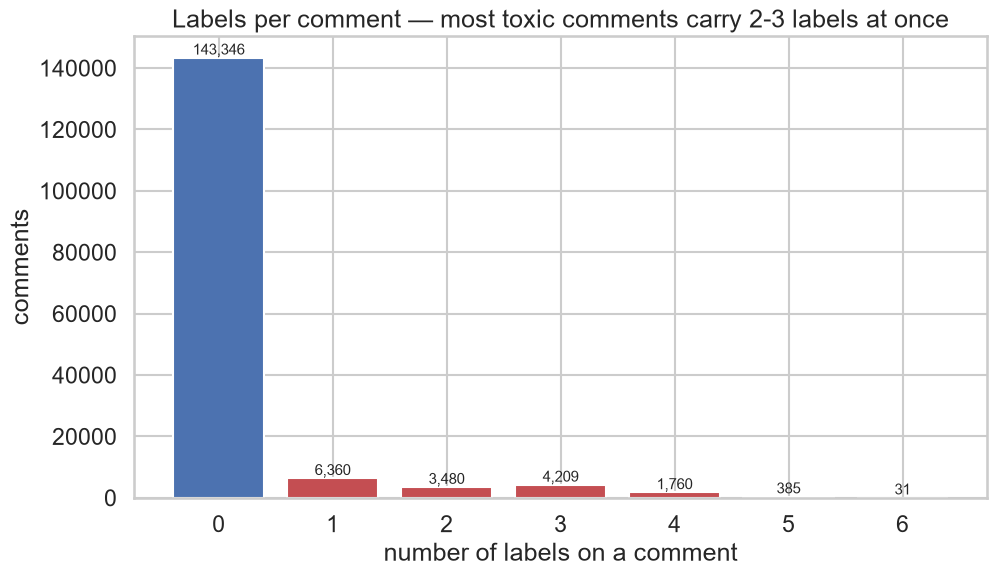

In [7]:
fig, ax = plt.subplots(figsize=(11, 6))
per = df['n_labels'].value_counts().sort_index()
bars = ax.bar(per.index.astype(str), per.values, color=[C_CLEAN] + [C_TOXIC] * (len(per) - 1))
for b, v in zip(bars, per.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f'{v:,}', ha='center', va='bottom', fontsize=11)
ax.set_title('Labels per comment — most toxic comments carry 2-3 labels at once')
ax.set_xlabel('number of labels on a comment')
ax.set_ylabel('comments')
fig.savefig(FIG_DIR / '02_labels_per_comment.png', dpi=140, bbox_inches='tight')
plt.show()

## 5. Figure 3 — Label correlation heatmap

**Why we look at this:** Pearson correlation between the binary labels quantifies co-occurrence. We expect `obscene`↔`insult`↔`toxic` to be strongly related (swearing is a common attack vector), while `threat` and `severe_toxic` sit mostly apart — they're rare, extreme behaviors. High correlation also warns us that per-class errors will be correlated (a comment the model gets wrong will likely be wrong on several labels at once).

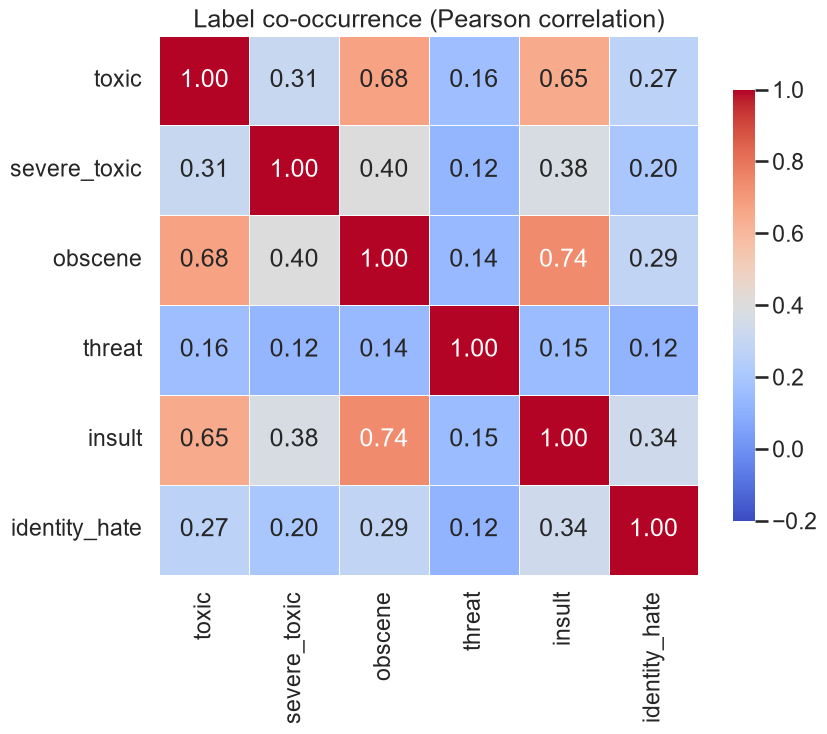

In [8]:
fig, ax = plt.subplots(figsize=(9, 7))
corr = df[LABELS].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-0.2, vmax=1,
            square=True, linewidths=0.5, cbar_kws={'shrink': 0.8}, ax=ax)
ax.set_title('Label co-occurrence (Pearson correlation)')
fig.savefig(FIG_DIR / '03_label_correlation.png', dpi=140, bbox_inches='tight')
plt.show()

## 6. Figure 4 — Comment length: clean vs toxic

**Why we look at this:** structural signals matter. Wikipedia talk-page discussion is long-form; attacks are often one-liners. If the distributions differ, a length feature could help a classical model — and for deep models it hints that most comments fit in a small token budget.

**Two plotting tricks here:**
- `stat='density'` — clean (143k) and toxic (16k) sets have very different sizes, so raw counts would just show two big blue bars.
- Capping at the 99th percentile — a few 5,000-word essays would crush everything else into one bar at zero.

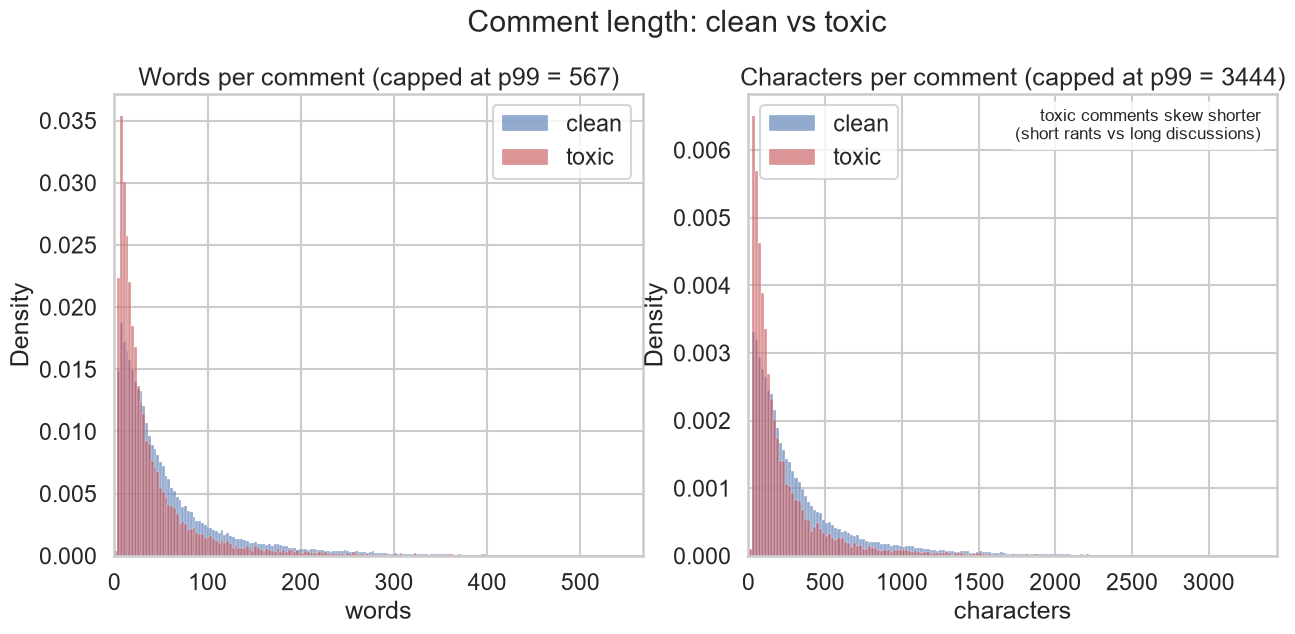

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
clean, toxic = df[df['is_toxic'] == 0], df[df['is_toxic'] == 1]

w_max = int(df['n_words'].quantile(0.99))
c_max = int(df['n_chars'].quantile(0.99))

sns.histplot(clean['n_words'], bins=np.arange(0, w_max, 3), stat='density',
             color=C_CLEAN, alpha=0.6, label='clean', ax=axes[0])
sns.histplot(toxic['n_words'], bins=np.arange(0, w_max, 3), stat='density',
             color=C_TOXIC, alpha=0.6, label='toxic', ax=axes[0])
axes[0].set_xlim(0, w_max)
axes[0].set_title(f'Words per comment (capped at p99 = {w_max})')
axes[0].set_xlabel('words')
axes[0].legend()

sns.histplot(clean['n_chars'], bins=np.arange(0, c_max, 20), stat='density',
             color=C_CLEAN, alpha=0.6, label='clean', ax=axes[1])
sns.histplot(toxic['n_chars'], bins=np.arange(0, c_max, 20), stat='density',
             color=C_TOXIC, alpha=0.6, label='toxic', ax=axes[1])
axes[1].set_xlim(0, c_max)
axes[1].set_title(f'Characters per comment (capped at p99 = {c_max})')
axes[1].set_xlabel('characters')
axes[1].legend()
axes[1].text(0.97, 0.97, 'toxic comments skew shorter\n(short rants vs long discussions)',
             transform=axes[1].transAxes, ha='right', va='top', fontsize=12,
             bbox=dict(boxstyle='round', fc='white', alpha=0.8))
fig.suptitle('Comment length: clean vs toxic', y=1.02)
fig.savefig(FIG_DIR / '04_length_distribution.png', dpi=140, bbox_inches='tight')
plt.show()

## 7. Figure 5 — Word clouds: the vocabulary of clean vs toxic

**Why we look at this:** a fast qualitative read of the domain. Clean comments talk about *articles, edits, sources, pages* — they're work discussions. Toxic comments are dominated by personal attacks.

**Two important knobs:**
- `stopwords=` — without removing English stopwords the cloud would be a wall of 'the/and/you'. We add a few tokenized fragments ('wa', 'ha', 'll') that sklearn-style tokenizers leave behind.
- `collocations=True` (default) — keeps word **pairs** like 'piece of', so toxic phrases survive as phrases instead of being scattered into single words.

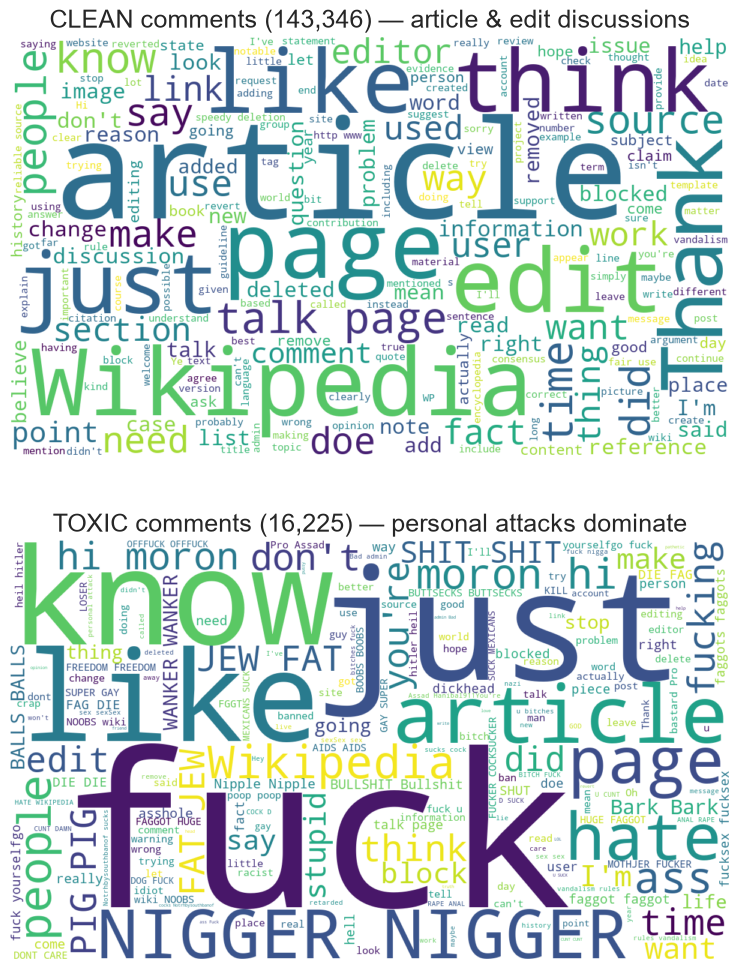

In [10]:
extra_stop = set(['don', 'should', 'now', 'wa', 'ha', 'll', 've']) | set(ENGLISH_STOP_WORDS)

def make_wc(texts):
    return WordCloud(width=1200, height=700, background_color='white',
                     stopwords=extra_stop, max_words=200, collocations=True,
                     colormap='viridis').generate(' '.join(texts.astype(str)))

clean, toxic = df[df['is_toxic'] == 0], df[df['is_toxic'] == 1]

fig, axes = plt.subplots(2, 1, figsize=(13, 12))
axes[0].imshow(make_wc(clean['comment_text']), interpolation='bilinear')
axes[0].set_title(f'CLEAN comments ({len(clean):,}) — article & edit discussions')
axes[1].imshow(make_wc(toxic['comment_text']), interpolation='bilinear')
axes[1].set_title(f'TOXIC comments ({len(toxic):,}) — personal attacks dominate')
for ax in axes:
    ax.axis('off')
fig.savefig(FIG_DIR / '05_wordclouds.png', dpi=140, bbox_inches='tight')
plt.show()

## 8. Figure 6 — Top bigrams per label: what defines each class

**Why we look at this:** the money chart for feature intuition. Bigrams (word pairs) capture phrases that unigrams miss — and here they basically *show you the decision boundary*: each label is defined by recognizable phrase patterns. This is exactly what a bag-of-words / TF-IDF model will latch onto, and why such simple models do surprisingly well on this challenge.

**Knobs:** `min_df=2` drops bigrams seen only once (typos, noise) before ranking; we take the top 12 per label.

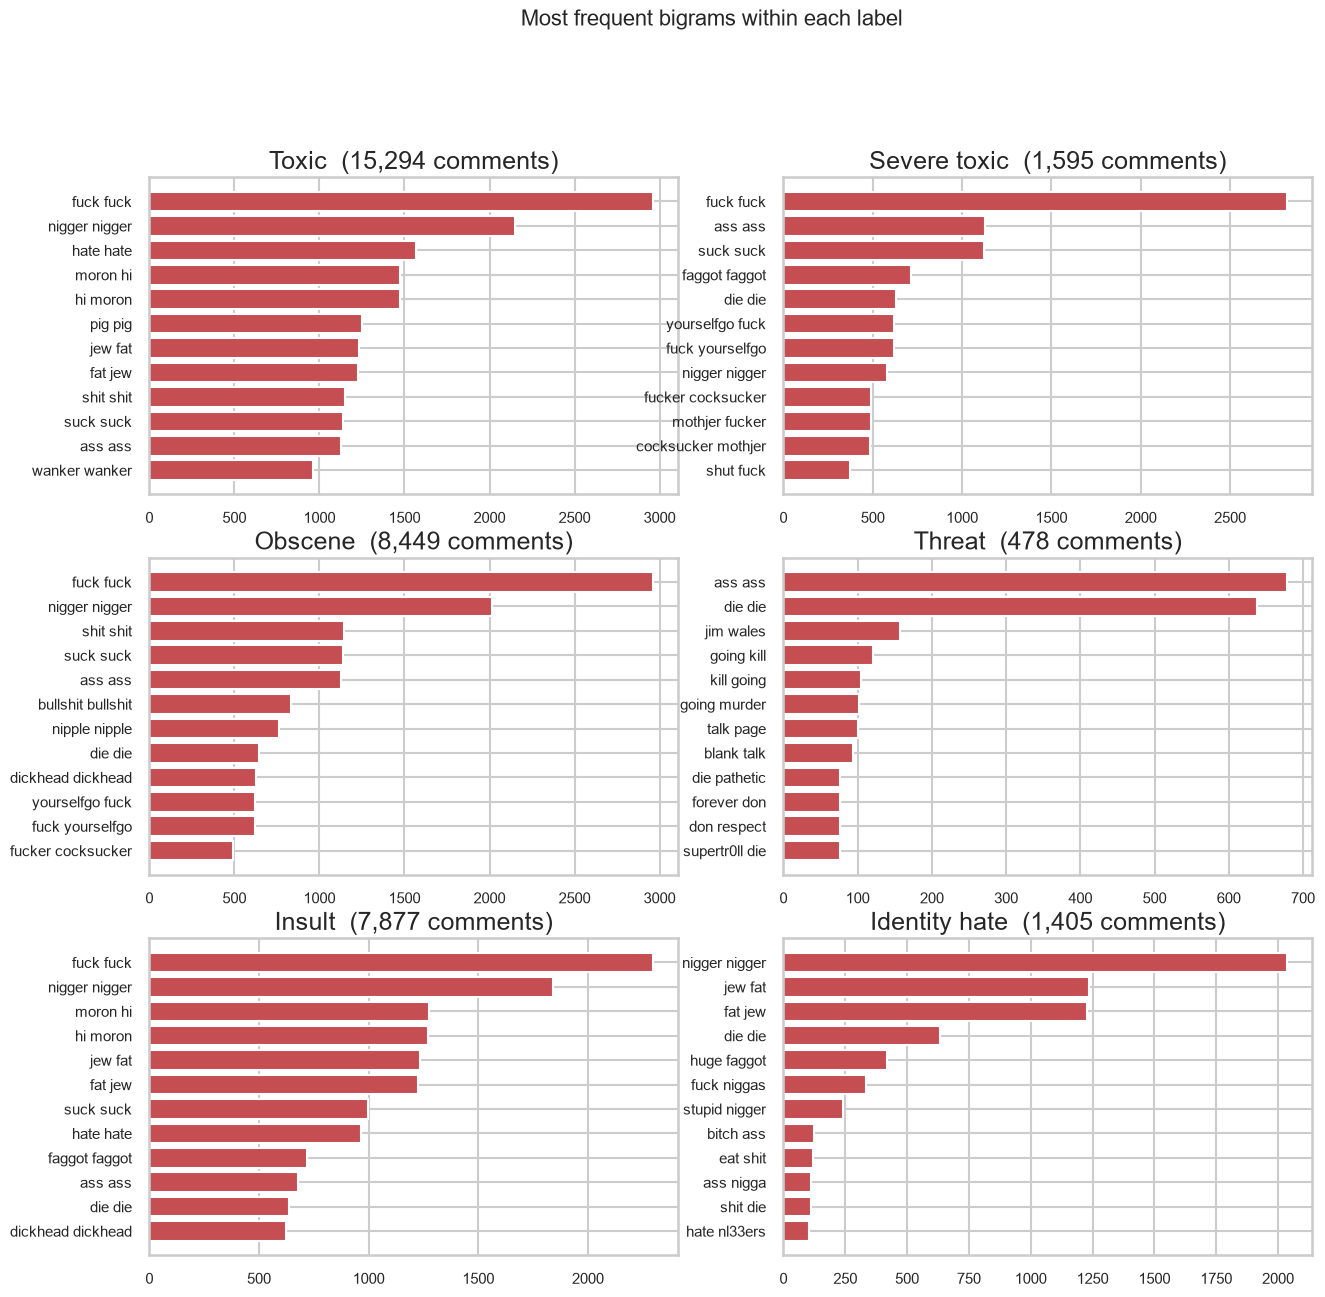

In [11]:
fig, axes = plt.subplots(3, 2, figsize=(15, 14))
for ax, label in zip(axes.flat, LABELS):
    subset = df.loc[df[label] == 1, 'comment_text']
    vec = CountVectorizer(ngram_range=(2, 2), stop_words='english', min_df=2)
    X = vec.fit_transform(subset)
    top = np.asarray(X.sum(axis=0)).ravel()
    names = np.array(vec.get_feature_names_out())
    idx = top.argsort()[-12:]          # top 12 bigrams
    idx = idx[np.argsort(top[idx])]    # ascending for barh
    ax.barh(names[idx], top[idx], color=C_TOXIC)
    ax.set_title(f'{PRETTY[label]}  ({int(counts[label]):,} comments)')
    ax.tick_params(labelsize=11)
fig.suptitle('Most frequent bigrams within each label', y=1.00, fontsize=16)
fig.savefig(FIG_DIR / '06_top_bigrams_per_label.png', dpi=140, bbox_inches='tight')
plt.show()

## 9. Figure 7 — Inside the 'toxic' class: conditional co-occurrence

**Why we look at this:** instead of symmetric correlation, ask a directed question: *given that a comment is labeled `toxic`, how often is it also `obscene` / `insult` / ...?* This is the kind of number you'd use to sanity-check model predictions (e.g. a comment predicted `threat` but flagged nothing else is suspicious, since threats almost always co-occur with `insult`/`toxic`).

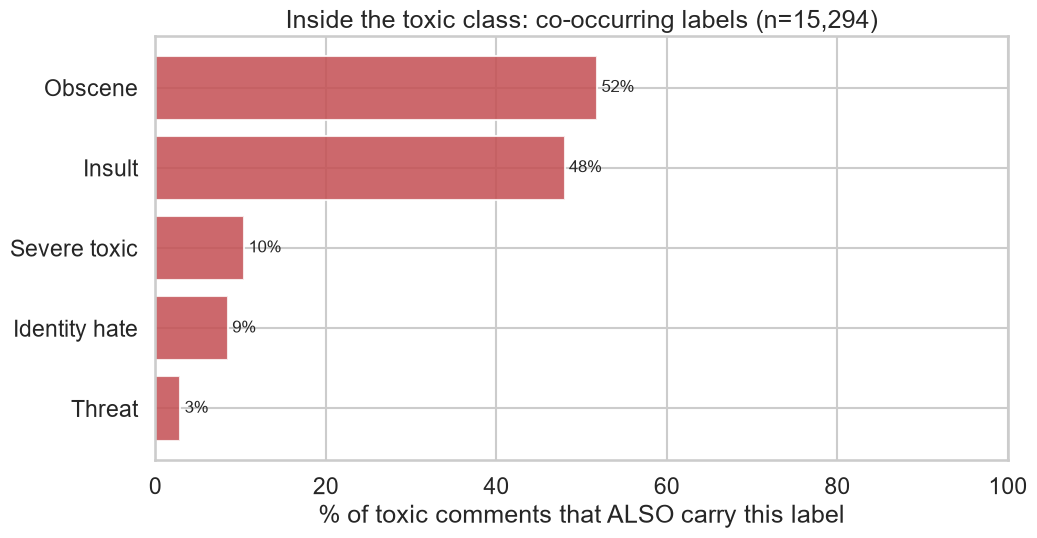

In [12]:
toxic_mask = df['toxic'] == 1
cond = (df.loc[toxic_mask, LABELS].sum() / toxic_mask.sum()).drop('toxic').sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(11, 5.5))
bars = ax.barh([PRETTY[i] for i in cond.index], cond.values * 100, color=C_TOXIC, alpha=0.85)
for b, v in zip(bars, cond.values):
    ax.text(v * 100 + 0.5, b.get_y() + b.get_height() / 2, f'{v * 100:.0f}%', va='center', fontsize=12)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel('% of toxic comments that ALSO carry this label')
ax.set_title(f'Inside the toxic class: co-occurring labels (n={int(toxic_mask.sum()):,})')
fig.savefig(FIG_DIR / '07_cooccurrence_within_toxic.png', dpi=140, bbox_inches='tight')
plt.show()

## 10. Key takeaways & what's next

**What the EDA told us:**
1. **Extreme imbalance** — `toxic` ~10%, `threat` ~0.3% → use per-class metrics (AUC, F1), never plain accuracy; consider class weights.
2. **Genuinely multi-label** — most labeled comments carry 2–3 labels → shared-representation models beat 6 independent models.
3. **Correlated labels** — `obscene`/`insult`/`toxic` travel together; `threat`/`severe_toxic` are isolated extremes.
4. **Toxic ⇒ shorter** — attacks are one-liners; length is a cheap auxiliary feature.
5. **Vocabulary is highly distinctive** — bigrams basically expose the classes → TF-IDF + linear models are a strong baseline; fine-tuned transformers then push the ceiling.

**Roadmap for the next notebooks:**
- `02` — text cleaning & TF-IDF baseline (logistic regression), first submission to Kaggle
- `03` — evaluation done right: per-class AUC, threshold tuning, error analysis on the worst examples
- `04` — modern approach: fine-tune a pretrained transformer (e.g. BERT/DistilBERT) and compare

Run order: this notebook only needs `data/train.csv` and writes 7 PNGs into `figures/`.